# Exploratory Analysis of Quantum Dot Blinking

## Dataset
qdb_20260824_102327.raw

## Aim
Explore the spatial and temporal fluorescence characteristics
of detected quantum dot candidates.

Initially, compare differences in brightness, fitted width,
and fluorescence variability.

## Research context
This analysis builds on the methods in
*A practical guide for wide-field imaging of quantum dot blinking*.

The aim is to investigate which measurements might eventually
help distinguish isolated emitters from unresolved clusters.

Candidate detection does not establish the number of quantum dots.

In [25]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find results from the selected experimental recording
results_root = Path("qd_blinking_results")

folders = sorted(
    results_root.glob("qdb_20260824_102327_raw_*"),
    key=lambda p: p.stat().st_mtime
)

if not folders:
    raise FileNotFoundError("No experimental analysis results found.")

folder = folders[-1]

# Load previously exported results
candidates = pd.read_csv(folder / "retained_candidates.csv")
statistics = pd.read_csv(folder / "trace_statistics.csv")
traces = pd.read_csv(folder / "extracted_traces.csv")

print("Dataset:", folder.name)
print("Retained candidates:", len(candidates))
print("Extracted traces:", traces["candidate_id"].nunique())
print("Total measurements:", len(traces))

Dataset: qdb_20260824_102327_raw_20261103T172454_915747Z
Retained candidates: 168
Extracted traces: 168
Total measurements: 168000


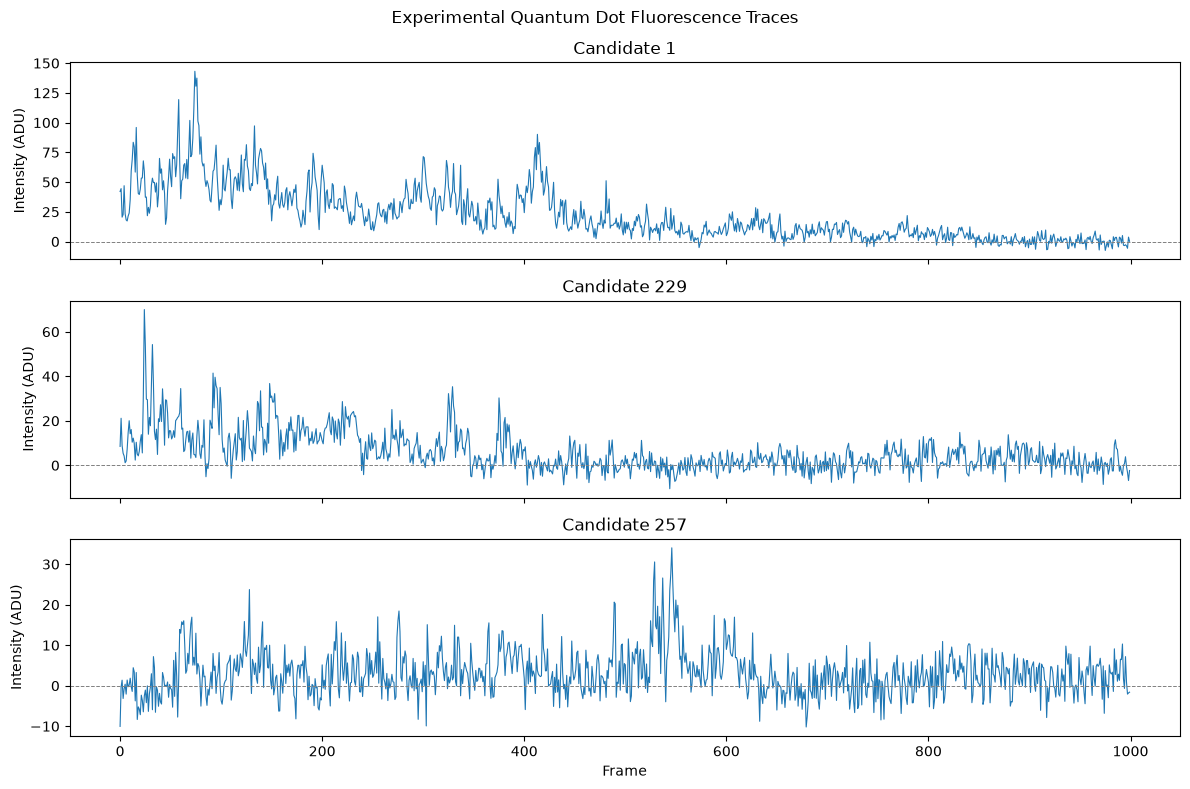

In [26]:
candidate_ids = [1, 229, 257]

fig, axes = plt.subplots(
    len(candidate_ids), 1,
    figsize=(12, 8),
    sharex=True
)

for ax, cid in zip(axes, candidate_ids):
    trace = traces[traces["candidate_id"] == cid]

    if trace["time_s"].notna().all():
        x = trace["time_s"]
        xlabel = "Time (s)"
    else:
        x = trace["frame"]
        xlabel = "Frame"

    ax.plot(
        x,
        trace["corrected_mean_counts"],
        linewidth=0.8
    )

    ax.axhline(0, linestyle="--", color="gray", linewidth=0.7)
    ax.set_ylabel("Intensity (ADU)")
    ax.set_title(f"Candidate {cid}")

axes[-1].set_xlabel(xlabel)

fig.suptitle("Experimental Quantum Dot Fluorescence Traces")
plt.tight_layout()
plt.show()

## Temporal changes in fluorescence intensity

The experimental traces exhibit substantial changes in
fluorescence intensity over time.

To investigate these changes, the mean corrected intensity
during the first and last 200 frames is compared.

This provides a descriptive measurement of temporal
brightness changes but does not independently establish
photobleaching or any particular blinking mechanism.

In [27]:
# Compare the beginning and end of each fluorescence trace

results = []

for cid, group in traces.groupby("candidate_id"):

    group = group.sort_values("frame")
    intensity = group["corrected_mean_counts"].to_numpy()

    early_mean = intensity[:200].mean()
    late_mean = intensity[-200:].mean()

    results.append({
        "candidate_id": cid,
        "early_mean": early_mean,
        "late_mean": late_mean,
        "intensity_change": late_mean - early_mean
    })

temporal_summary = pd.DataFrame(results)

display(
    temporal_summary[
        temporal_summary["candidate_id"].isin([1, 229, 257])
    ].round(2)
)

,candidate_id,early_mean,late_mean,intensity_change
0,1,51.24,1.80,-49.44
147,229,15.34,2.57,-12.78
163,257,2.32,2.51,0.18


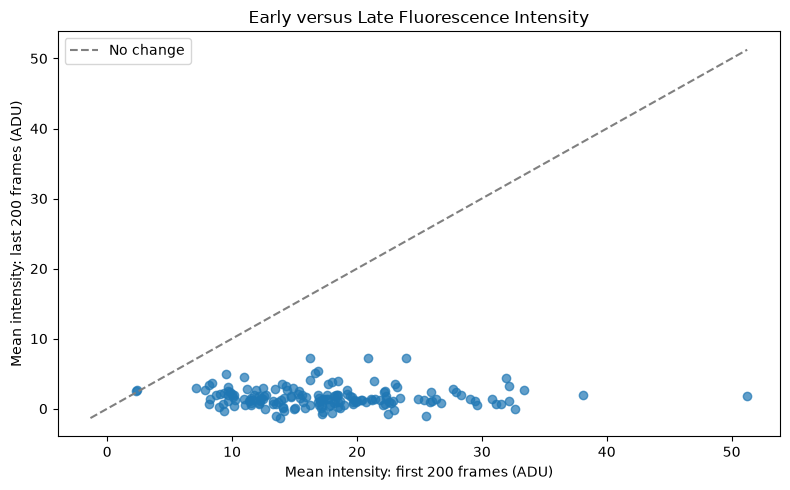

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    temporal_summary["early_mean"],
    temporal_summary["late_mean"],
    alpha=0.7
)

low = min(
    temporal_summary["early_mean"].min(),
    temporal_summary["late_mean"].min()
)

high = max(
    temporal_summary["early_mean"].max(),
    temporal_summary["late_mean"].max()
)

ax.plot([low, high], [low, high],
        linestyle="--", color="gray",
        label="No change")

ax.set_xlabel("Mean intensity: first 200 frames (ADU)")
ax.set_ylabel("Mean intensity: last 200 frames (ADU)")
ax.set_title("Early versus Late Fluorescence Intensity")
ax.legend()

plt.tight_layout()
plt.show()

## Population-wide fluorescence evolution

The early-versus-late comparison suggests that many detected
fluorescent features become dimmer during the recording.

To investigate whether this behaviour is shared across the
candidate population, the mean and median background-corrected
intensity are calculated for every frame.

These statistics describe the detected candidate population.
They do not establish the physical cause of fluorescence loss.

Potential explanations include photobleaching, photodarkening,
long-lived dark states and changes in experimental conditions.

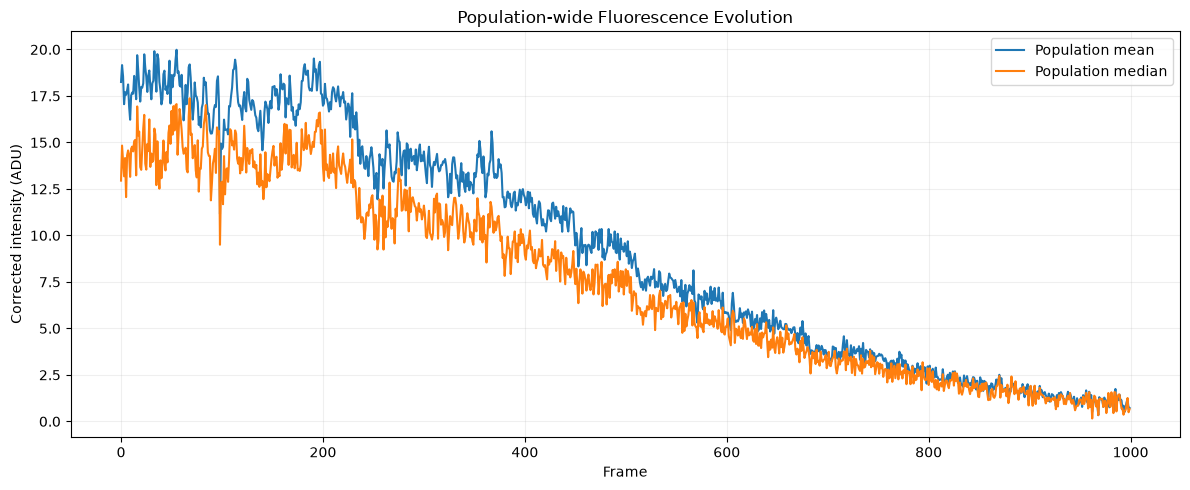

In [29]:
# Calculate population-wide fluorescence statistics

population = (
    traces.groupby("frame")["corrected_mean_counts"]
    .agg(["mean", "median", "std"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    population["frame"],
    population["mean"],
    label="Population mean",
    linewidth=1.5
)

ax.plot(
    population["frame"],
    population["median"],
    label="Population median",
    linewidth=1.5
)

ax.set_xlabel("Frame")
ax.set_ylabel("Corrected intensity (ADU)")
ax.set_title("Population-wide Fluorescence Evolution")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Population-Wide Fluorescence Evolution

The graph shows the mean and median background-corrected fluorescence intensity across all 168 retained candidates over the 1,000-frame recording.

Both the population mean (blue) and median (orange) show a substantial decrease in fluorescence intensity over time, falling from approximately 18 and 14 ADU respectively to around 1 ADU by the end of the recording. Although short-term fluctuations are present, the overall trend is a progressive reduction in fluorescence across the candidate population.

The mean remains consistently above the median, particularly during the early frames, suggesting that a subset of brighter candidates contributes disproportionately to the average intensity.

This behaviour could be consistent with **photobleaching or photodarkening**, where quantum dots lose fluorescence under sustained illumination. However, changes in experimental conditions, such as excitation intensity or focus drift, could also contribute. Further investigation would be required to determine the physical cause.

### Summary of Exploratory Analysis So Far

- Successfully reproduced the original analysis pipeline on the experimental recording `qdb_20260824_102327.raw`.
- Detected **264 fluorescent features**, of which **168 passed the Gaussian-fitting and quality-selection criteria**.
- Extracted 1,000-frame background-corrected intensity traces for all 168 retained candidates.
- Examined individual candidates, identifying considerable differences in brightness, intensity fluctuations and temporal behaviour.
- Compared the first and last 200 frames, finding that most candidates exhibited a substantial reduction in fluorescence intensity.
- Confirmed through population-wide analysis that fluorescence generally decreases throughout the recording.

### Initial Conclusions

The experimental traces exhibit considerably more complex behaviour than the synthetic demonstration data. In particular, the widespread decline in fluorescence suggests that time-dependent intensity changes may need to be accounted for when developing automated blinking analysis methods.

These observations provide an initial understanding of the dataset and highlight important considerations for future work, particularly the challenge of distinguishing individual quantum dots from unresolved clusters using their fluorescence behaviour.

## Spatial Excitation Profile Analysis

### Aim

The aim of this analysis is to investigate the spatial variation in fluorescence intensity across the field of view and determine whether it could provide an approximate indication of the nonuniform excitation intensity experienced by individual quantum dots (QDs).

The excitation laser was deliberately defocused to illuminate a larger region of the sample. Consequently, QDs at different positions may experience different local excitation intensities despite the nominal laser power remaining constant.

### Method

A time-averaged image is calculated from the experimental video to visualise the overall spatial intensity distribution. A spatial median filter followed by Gaussian smoothing is used to suppress localised bright features and estimate the broad background intensity profile.

The resulting image is examined alongside a horizontal intensity cross-section to characterise the variation across the field of view.

### Limitations

The measured image intensity represents camera-recorded light rather than a direct measurement of excitation irradiance. Spatial variations may also arise from QD concentration, out-of-focus fluorescence, optical scattering and detection nonuniformity.

The current analysis uses an 8-bit cropped MP4 rather than the original 16-bit RAW acquisition. Consequently, intensities are interpreted as relative video grey levels rather than calibrated camera counts or optical power.

This analysis is therefore exploratory. The spatial profile may eventually be used as a relative excitation-intensity proxy, but this assumption must be assessed before drawing conclusions about excitation-dependent QD blinking.

In [30]:

from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import median_filter, gaussian_filter
from skimage.feature import peak_local_max

# Select experimental video
VIDEO_PATH = Path(
    "/Users/william/Documents/UNI/MASTERS PROJECT/WT_MastersRepo/qd_blinking_supplementary_code/Exp_Data/102327_cropped.mp4"
)

if not VIDEO_PATH.is_file():
    raise FileNotFoundError(
        f"Video not found: {VIDEO_PATH.resolve()}\n"
        "Place the video beside the notebook or update VIDEO_PATH."
    )

# Adjustable exploratory parameters
FRAME_STEP = 5
MEDIAN_SIZE = 41
SMOOTHING_SIGMA = 20

print(f"Selected video: {VIDEO_PATH.name}")


Selected video: 102327_cropped.mp4


Video dimensions: (500, 500)
Frames used: 200
Frame rate: 20.00 fps


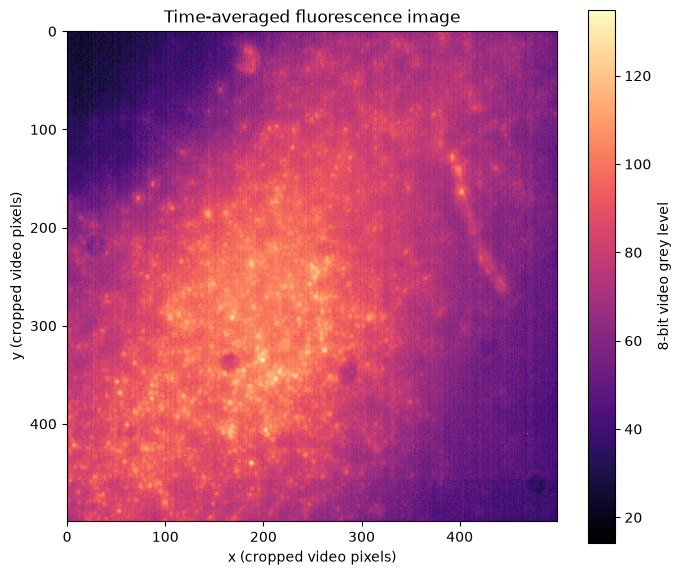

In [31]:

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Could not open the selected video.")

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)

sum_image = None
frames_used = 0

try:
    for frame_index in range(frame_count):
        success, frame = cap.read()

        if not success:
            break

        if frame_index % FRAME_STEP != 0:
            continue

        gray = cv2.cvtColor(
            frame, cv2.COLOR_BGR2GRAY
        ).astype(np.float64)

        if sum_image is None:
            sum_image = np.zeros_like(gray)

        sum_image += gray
        frames_used += 1
finally:
    cap.release()

if frames_used == 0:
    raise RuntimeError("No video frames could be read.")

mean_image = sum_image / frames_used

print(f"Video dimensions: {mean_image.shape}")
print(f"Frames used: {frames_used}")
print(f"Frame rate: {fps:.2f} fps")

plt.figure(figsize=(7, 6))

plt.imshow(mean_image, cmap="magma", origin="upper")
plt.colorbar(label="8-bit video grey level")

plt.title("Time-averaged fluorescence image")
plt.xlabel("x (cropped video pixels)")
plt.ylabel("y (cropped video pixels)")

plt.tight_layout()
plt.show()


### Estimating the Broad Spatial Background

The time-averaged image contains both localised fluorescent features and a broad spatial intensity distribution.

To investigate the broad distribution separately, a median filter is applied to reduce the influence of small bright and dark features. Gaussian smoothing is subsequently applied to estimate the slowly varying background.

The resulting profile is intended to represent the broad spatial variation in recorded image brightness. It does not directly measure excitation irradiance.

The filtering parameters are initially selected for exploratory visual analysis and will need to be assessed for sensitivity and possible distortion of the underlying spatial profile.

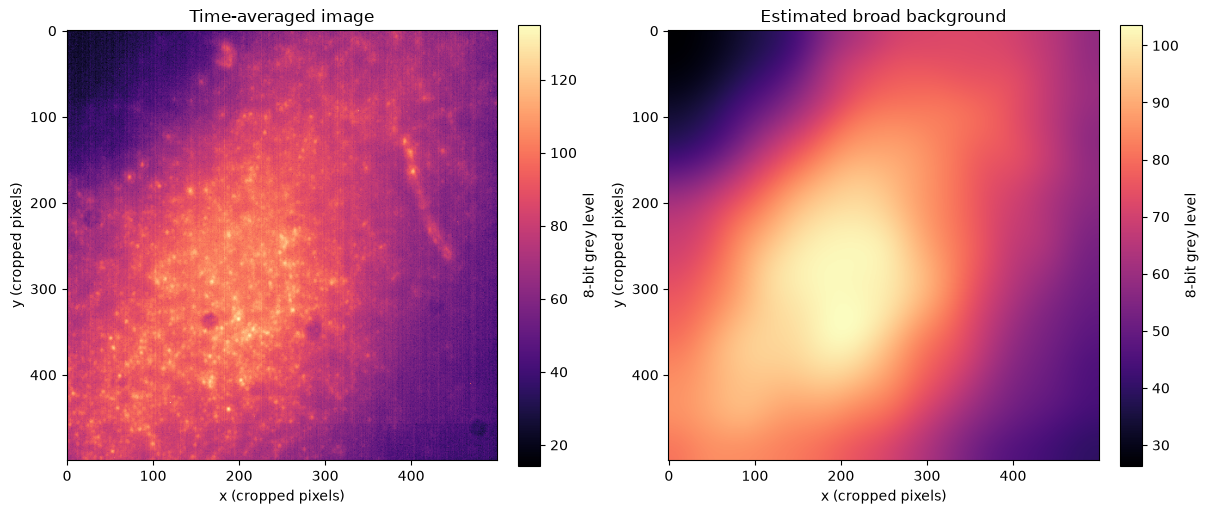

Estimated background range: 26.34 to 103.59


In [32]:

# Suppress localised features using a spatial median filter
median_image = median_filter(
    mean_image,
    size=MEDIAN_SIZE,
    mode="reflect"
)

# Smooth the remaining broad spatial structure
background_image = gaussian_filter(
    median_image,
    sigma=SMOOTHING_SIGMA
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    constrained_layout=True
)

im0 = axes[0].imshow(
    mean_image,
    cmap="magma",
    origin="upper"
)
axes[0].set_title("Time-averaged image")

im1 = axes[1].imshow(
    background_image,
    cmap="magma",
    origin="upper"
)
axes[1].set_title("Estimated broad background")

for ax in axes:
    ax.set_xlabel("x (cropped pixels)")
    ax.set_ylabel("y (cropped pixels)")

fig.colorbar(
    im0, ax=axes[0],
    label="8-bit grey level"
)

fig.colorbar(
    im1, ax=axes[1],
    label="8-bit grey level"
)

plt.show()

print(
    "Estimated background range:",
    f"{background_image.min():.2f} to "
    f"{background_image.max():.2f}"
)


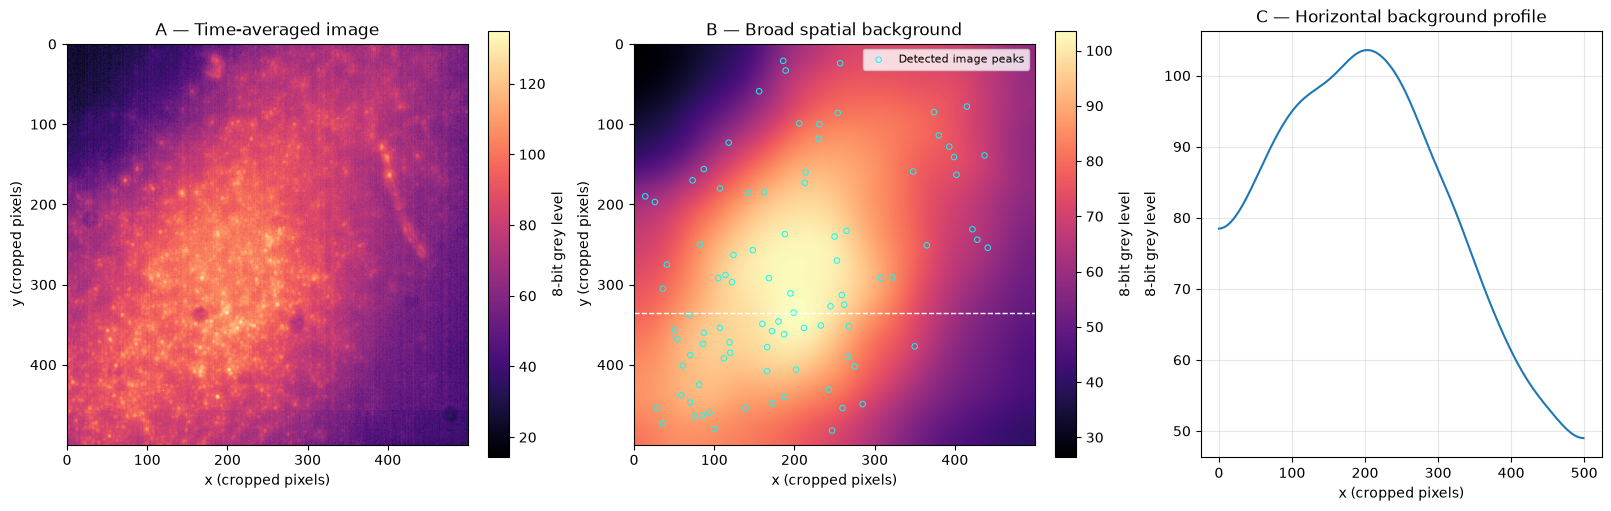

Detected image peaks displayed: 90
Broad background maximum at: (203, 335)


In [33]:

# Detect local positive features above the estimated background
contrast_image = gaussian_filter(
    mean_image - background_image,
    sigma=1.2
)

peaks = peak_local_max(
    contrast_image,
    min_distance=7,
    threshold_abs=8,
    exclude_border=12
)

# Show up to 90 strongest peaks for visual clarity
peaks = sorted(
    peaks,
    key=lambda p: contrast_image[tuple(p)],
    reverse=True
)[:90]

peaks = np.asarray(peaks, dtype=int).reshape(-1, 2)

# Locate the maximum of the broad background
y_peak, x_peak = np.unravel_index(
    np.argmax(background_image),
    background_image.shape
)

# Horizontal cross-section through that maximum
horizontal_profile = background_image[y_peak, :]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    constrained_layout=True
)

# Panel A
im0 = axes[0].imshow(mean_image, cmap="magma")
axes[0].set_title("A — Time-averaged image")

fig.colorbar(
    im0, ax=axes[0],
    label="8-bit grey level"
)

# Panel B
im1 = axes[1].imshow(background_image, cmap="magma")
axes[1].set_title("B — Broad spatial background")

if len(peaks) > 0:
    axes[1].scatter(
        peaks[:, 1],
        peaks[:, 0],
        s=16,
        facecolors="none",
        edgecolors="cyan",
        linewidths=0.7,
        label="Detected image peaks"
    )
    axes[1].legend(fontsize=8)

axes[1].axhline(
    y_peak,
    color="white",
    linestyle="--",
    linewidth=1
)

fig.colorbar(
    im1, ax=axes[1],
    label="8-bit grey level"
)

# Panel C
axes[2].plot(
    np.arange(background_image.shape[1]),
    horizontal_profile
)

axes[2].set_title("C — Horizontal background profile")
axes[2].set_xlabel("x (cropped pixels)")
axes[2].set_ylabel("8-bit grey level")
axes[2].grid(alpha=0.3)

for ax in axes[:2]:
    ax.set_xlabel("x (cropped pixels)")
    ax.set_ylabel("y (cropped pixels)")

plt.show()

print(f"Detected image peaks displayed: {len(peaks)}")
print(f"Broad background maximum at: ({x_peak}, {y_peak})")


### Initial Interpretation and Next Steps

The time-averaged image shows a nonuniform spatial intensity distribution, with a broad region of increased brightness surrounded by areas of lower recorded intensity.

This distribution is consistent with the expected influence of a defocused excitation beam, which may produce different local excitation conditions across the sample. However, the image alone does not establish that the measured background intensity is proportional to the incident laser irradiance.

The initial analysis therefore provides a spatial brightness map that can be used to investigate potential relationships between local imaging conditions and QD fluorescence dynamics.

The next stage will involve extracting temporal fluorescence traces from individual candidate features and examining whether their blinking-related statistics or fluorescence decay vary systematically with the estimated local background intensity.

Before drawing physical conclusions, the analysis will need to account for signal-to-noise ratio, intrinsic differences between emitters, spatially varying sample density and the limitations of the compressed video data.


## Spatial Background Intensity and QD Fluorescence Behaviour

### Aim

The previous analysis identified a broad, nonuniform spatial intensity distribution within the experimental recording. This may be associated with the defocused laser excitation profile.

The aim of this section is to investigate whether the fluorescence behaviour of candidate quantum dots varies systematically with their position within this spatial brightness distribution.

### Method

The original 16-bit RAW recording will be used to generate a time-averaged fluorescence image. A smoothed spatial background will then be estimated to suppress localised fluorescent features.

The fitted coordinates of previously retained QD candidates will be overlaid on this background image. Each candidate will be assigned a local background intensity based on its spatial position.

These values will be compared against temporal fluorescence statistics, initially focusing on the change in background-corrected intensity between the beginning and end of the recording.

### Important limitation

The spatial background represents measured camera intensity rather than calibrated excitation irradiance. Any relationship between local background brightness and fluorescence behaviour must therefore be interpreted as an observational association rather than direct evidence of excitation-power dependence.

## Loading Original Recording ##
This uses the functions already provided in `qd_blinking.py`.

Loaded: qdb_20260824_102327.raw
Video shape: (1000, 1024, 1024)


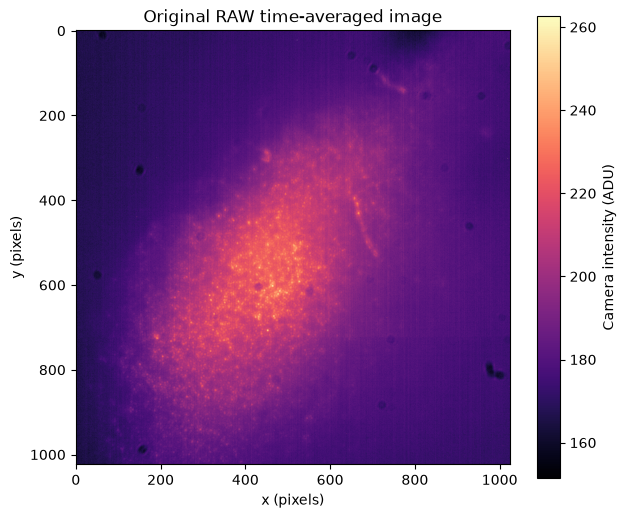

In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import median_filter, gaussian_filter
from qd_blinking import load_raw_video, projections, select_input_file

# Select the original 102327 RAW recording
raw_path = Path("/Users/william/Documents/UNI/MASTERS PROJECT/WT_MastersRepo/qd_blinking_supplementary_code/Exp_Data/qdb_20260824_102327.raw")

video = load_raw_video(
    raw_path,
    width=1024,
    height=1024,
    header_bytes=0,
    dtype="<u2",
    expected_frames=1000
)

# Existing function from qd_blinking.py
mean_image, max_image = projections(video)

print("Loaded:", raw_path.name)
print("Video shape:", video.shape)

plt.figure(figsize=(7, 6))
plt.imshow(mean_image, cmap="magma")
plt.colorbar(label="Camera intensity (ADU)")
plt.title("Original RAW time-averaged image")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.show()


## Estimating the broad spatial background ##
Lets reuse the filtering approach from earlier but apply it to this original image.

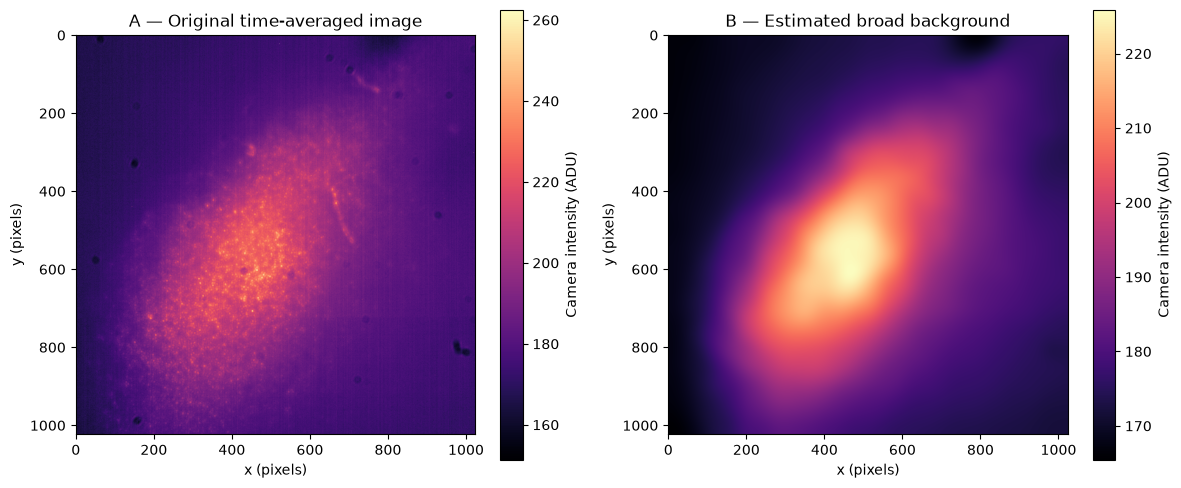

In [35]:

# Exploratory filtering parameters
MEDIAN_SIZE = 41
SMOOTHING_SIGMA = 20

median_image = median_filter(
    mean_image,
    size=MEDIAN_SIZE,
    mode="reflect"
)

background_image_raw = gaussian_filter(
    median_image,
    sigma=SMOOTHING_SIGMA
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(mean_image, cmap="magma")
axes[0].set_title("A — Original time-averaged image")
fig.colorbar(im0, ax=axes[0], label="Camera intensity (ADU)")

im1 = axes[1].imshow(background_image_raw, cmap="magma")
axes[1].set_title("B — Estimated broad background")
fig.colorbar(im1, ax=axes[1], label="Camera intensity (ADU)")

for ax in axes:
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")

plt.tight_layout()
plt.show()


This is still a smoothed fluorescence-background estimate, not a directly measured exitation irradiance map.

## Overlaying the existing QD candidate positions.
We will use the exported coordinates rather than running another detection algorithm.

Retained candidates: 168
Extracted trace rows: 168000


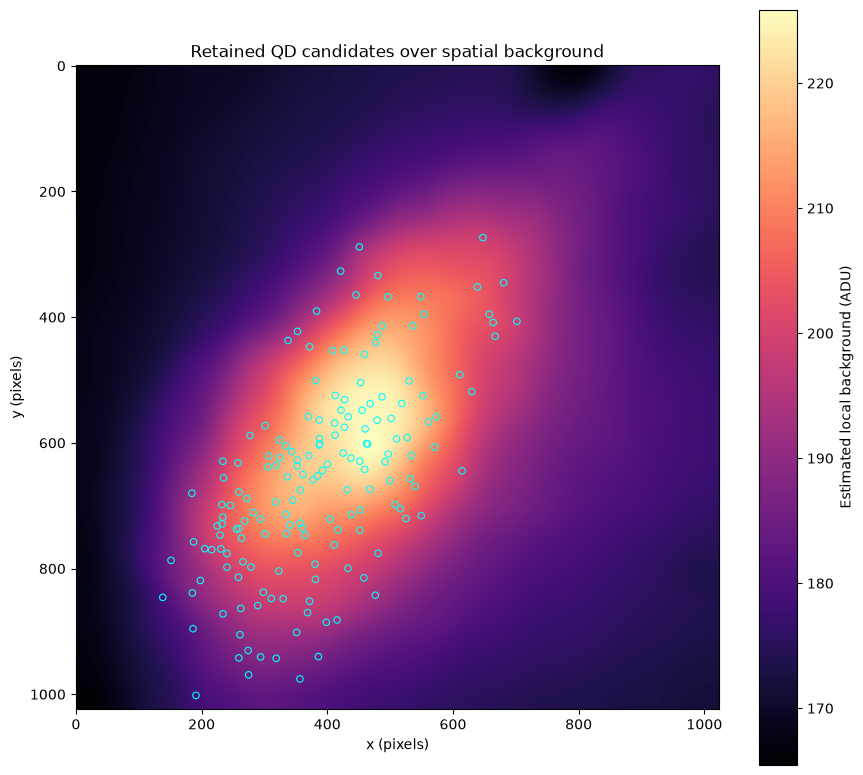

In [37]:

from pathlib import Path

# Set this to your existing qd_blinking_results run folder
results_dir = Path(
    input("Paste the results folder path: ").strip().strip('"').strip("'")
).expanduser()

candidates = pd.read_csv(
    results_dir / "retained_candidates.csv"
)

traces = pd.read_csv(
    results_dir / "extracted_traces.csv"
)

print("Retained candidates:", len(candidates))
print("Extracted trace rows:", len(traces))

# Validate that coordinates belong to this image
assert candidates["x"].between(
    0, mean_image.shape[1] - 1
).all()

assert candidates["y"].between(
    0, mean_image.shape[0] - 1
).all()

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(background_image_raw, cmap="magma")

ax.scatter(
    candidates["x"],
    candidates["y"],
    s=22,
    facecolors="none",
    edgecolors="cyan",
    linewidths=0.8
)

ax.set_title("Retained QD candidates over spatial background")
ax.set_xlabel("x (pixels)")
ax.set_ylabel("y (pixels)")

plt.colorbar(im, ax=ax, label="Estimated local background (ADU)")
plt.tight_layout()
plt.show()


The candidate locations are overlaid on the broad background, rather than the arbitrary 90 image peaks from our earlier analysis.

## Assinging local background values to each QD ##

Now we are going to link each candidate to the estimate brightness at its position.

In [38]:

# Rounded coordinates are used to sample the image
x_idx = np.rint(candidates["x"]).astype(int).to_numpy()
y_idx = np.rint(candidates["y"]).astype(int).to_numpy()

candidates = candidates.copy()

candidates["local_spatial_background"] = (
    background_image_raw[y_idx, x_idx]
)

display(
    candidates[
        [
            "candidate_id",
            "x",
            "y",
            "R",
            "local_spatial_background"
        ]
    ].head(10)
)


,candidate_id,x,y,R,local_spatial_background
0,1,452.800828,706.836582,1.637609,212.350303
1,2,464.054173,601.701621,1.684931,225.854840
2,3,667.021776,430.300938,2.022593,201.327972
3,4,205.045549,768.342618,1.578358,196.264949
4,5,318.990623,635.325971,1.591299,214.173278
5,6,527.175193,591.486405,1.803162,220.600793
6,10,337.570626,437.032278,1.623447,196.219384
7,12,151.308710,786.949598,1.678072,185.066625
8,14,224.744872,732.201358,1.516674,201.882913
9,15,433.411902,558.475863,1.850405,224.578432


This gives each candidate a spatial background value in camera ADU.

## Compare fluorescence decay against local background ##
Now we calculate the mean corrected fluorescence in the first and last 200 frames. This is the same as early-versus-late measure used earlier in this project file.

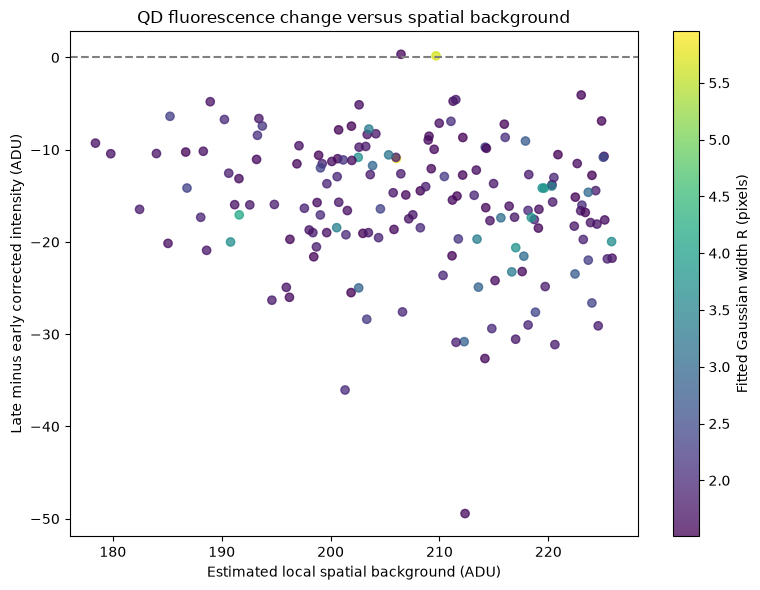

,candidate_id,local_spatial_background,early_mean,late_mean,intensity_change
0,1,212.350303,51.242321,1.801071,-49.441250
1,2,225.854840,22.884444,1.127407,-21.757037
2,3,201.327972,38.067963,2.019444,-36.048519
3,4,196.264949,22.152593,2.439444,-19.713148
4,5,214.173278,32.652115,0.017115,-32.635000
5,6,220.600793,32.198036,1.072143,-31.125893
6,10,196.219384,26.743981,0.743426,-26.000556
7,12,185.066625,23.183889,3.030926,-20.152963
8,14,201.882913,27.900000,2.410862,-25.489138
9,15,224.578432,29.624032,0.531452,-29.092581


In [39]:

# Select first and last 200 frames for each candidate
early = (
    traces[traces["frame"] < 200]
    .groupby("candidate_id")["corrected_mean_counts"]
    .mean()
    .rename("early_mean")
)

last_frame = traces["frame"].max()

late = (
    traces[traces["frame"] > last_frame - 200]
    .groupby("candidate_id")["corrected_mean_counts"]
    .mean()
    .rename("late_mean")
)

comparison = (
    candidates
    .merge(early, on="candidate_id")
    .merge(late, on="candidate_id")
)

# Absolute intensity change
comparison["intensity_change"] = (
    comparison["late_mean"] - comparison["early_mean"]
)

fig, ax = plt.subplots(figsize=(8, 6))

scatter = ax.scatter(
    comparison["local_spatial_background"],
    comparison["intensity_change"],
    c=comparison["R"],
    cmap="viridis",
    alpha=0.75
)

ax.axhline(0, color="grey", linestyle="--")

ax.set_xlabel("Estimated local spatial background (ADU)")
ax.set_ylabel("Late minus early corrected intensity (ADU)")
ax.set_title("QD fluorescence change versus spatial background")

plt.colorbar(scatter, ax=ax, label="Fitted Gaussian width R (pixels)")
plt.tight_layout()
plt.show()

display(
    comparison[
        [
            "candidate_id",
            "local_spatial_background",
            "early_mean",
            "late_mean",
            "intensity_change"
        ]
    ].head(10)
)


How to interpret this graph:
- A negatiev intensity change indicates that a candidate was dimmer during the final 200 frames than during the first 200 frames.
- If more negative changes tend to occur in regions of higher background intensity, that would indicate an assocaition worth exploring.

However, this would not yet prove higher excitation power causes faster photodarkening, because we haven't established that the broad fluorescence background is proportional to local excitation irradiance. 

Brighter candidates may also have a greater absolute decrease simply because they started brighter.

This will be the subsequent analysis, where we will examine normalised changes, background stability, candidate brightness and fitted width.

## Question: ##
Does the observed fluorescence decay depend on spation position, or is a similar proportional decline occuring across the whole sample?


I think there to be two main possibilites;

1) Spatial Dependance: Candidates in brighter-background regions consistently lose a greater fraction of their fluorescence.
2) Shared Temporal decline: Candidates lose similar proportions of their inital brightness, regardless of spatial position.

Our current graph cannot distinguish these possibilites reliably because it's based on absolute intensity changes...

## Normalised Fluorescence Change ##
We are going to restrict the inital comparison to candidates whose early mean exceeds 5 ADU, to reduce instability when dividing by small values.

(This is an exploratory cutoff, not validated signal-to-noise threshold)

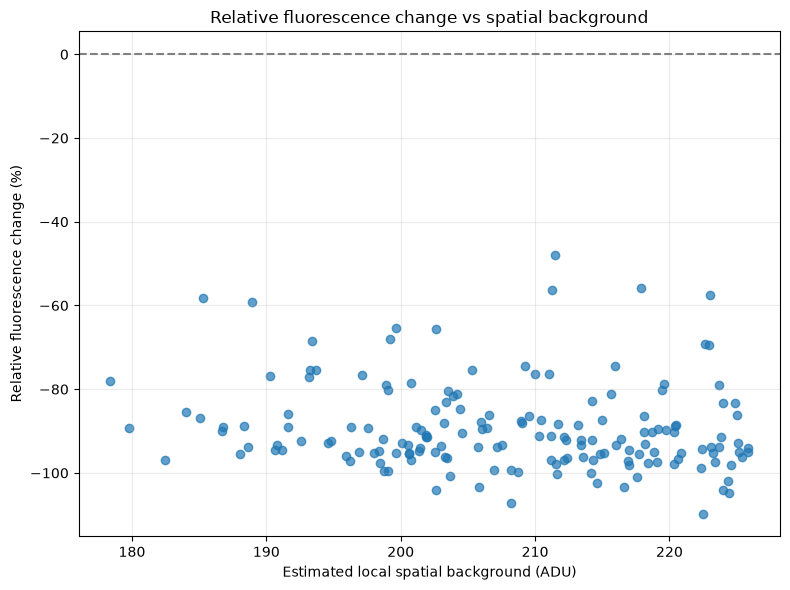

Candidates included: 166
Spearman correlation: -0.192
Exploratory p-value: 0.01339


,candidate_id,early_mean,late_mean,relative_change_pct
0,1,51.242321,1.801071,-96.485188
1,2,22.884444,1.127407,-95.073477
2,3,38.067963,2.019444,-94.695160
3,4,22.152593,2.439444,-88.987996
4,5,32.652115,0.017115,-99.947583
5,6,32.198036,1.072143,-96.670161
6,10,26.743981,0.743426,-97.220212
7,12,23.183889,3.030926,-86.926585
8,14,27.900000,2.410862,-91.358917
9,15,29.624032,0.531452,-98.206012


In [40]:

from scipy.stats import spearmanr

# Avoid unstable ratios for very dim initial candidates
MIN_EARLY_INTENSITY = 5.0

normalised = comparison.loc[
    comparison["early_mean"] > MIN_EARLY_INTENSITY
].copy()

# Relative fluorescence change, expressed as percentage
normalised["relative_change_pct"] = (
    100 * (
        normalised["late_mean"] - normalised["early_mean"]
    ) / normalised["early_mean"]
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    normalised["local_spatial_background"],
    normalised["relative_change_pct"],
    alpha=0.7
)

ax.axhline(0, color="grey", linestyle="--")

ax.set_xlabel("Estimated local spatial background (ADU)")
ax.set_ylabel("Relative fluorescence change (%)")
ax.set_title("Relative fluorescence change vs spatial background")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

rho, p_value = spearmanr(
    normalised["local_spatial_background"],
    normalised["relative_change_pct"]
)

print(f"Candidates included: {len(normalised)}")
print(f"Spearman correlation: {rho:.3f}")
print(f"Exploratory p-value: {p_value:.4g}")

display(
    normalised[
        [
            "candidate_id",
            "early_mean",
            "late_mean",
            "relative_change_pct"
        ]
    ].head(10)
)


The Spearman correlation coeffecient, $\rho$, measures whtether two quantities tend to increase or decrease together.

- Near 1: Strong positive monotonic association
- Near 0: Little Evidence of a monotonic association
- Near -1: Strong negative monotonic association

So our results of -0.192 indicates a weak tendency for QDs in regions with higher estimated spatial background to show larger proportional fluorescence losses. Our p-value is about 0.0134, under the assumption of the correlation test this is evidence against the hypothesis of no monotonic association. However, statistical signficiance does not tell us that the relationship is strong, physically meaningful, or caused by laser exictation.

The fluorescence decline is also a notable results, with most candidates losing approximately 80-100% of their inital background-corrected brightness. This suggests that the fluorescence loss is widespread rather than restircted to a smaller number of bright candidates. Though it should be noted this could be for differing reasons, like photodarkening or moving out of focus to name a few.

## Temporal Evolution of the Spatial Background

### Aim

Previous analysis revealed a substantial decrease in the background-corrected fluorescence intensity of most retained QD candidates over the course of the recording. A weak negative association was also observed between the relative fluorescence change and the estimated local spatial background intensity.

Before interpreting these observations as evidence of excitation-dependent photodarkening or blinking behaviour, it is important to investigate whether the broad spatial background itself changes during the recording.

### Method

The original 16-bit RAW recording is divided into early and late periods, corresponding to the first and last 200 frames.

Time-averaged images are calculated for each period using the existing analysis functions. Spatial median filtering and Gaussian smoothing are applied using the same parameters as the previous background analysis.

The resulting background maps are compared to investigate changes in the spatial brightness distribution. The analysis will also examine background intensity as a function of frame number at selected positions within the field of view.

### Interpretation

If the broad spatial background remains relatively stable while the QD fluorescence declines, this would suggest that the two signals exhibit different temporal behaviour.

If both decline, this may indicate a shared process or experimental influence, although background photodarkening, changes in illumination and other optical effects cannot be distinguished from these observations alone.

The estimated background remains a measurement of camera-recorded intensity rather than a direct measurement of excitation irradiance.

## Comparing early and late spatial background maps ##
We're going to use the `video` variable already loaded from the original RAW file. 

We'll also reuse the existing `projections()` function rather than re-writing the time-averaged code.

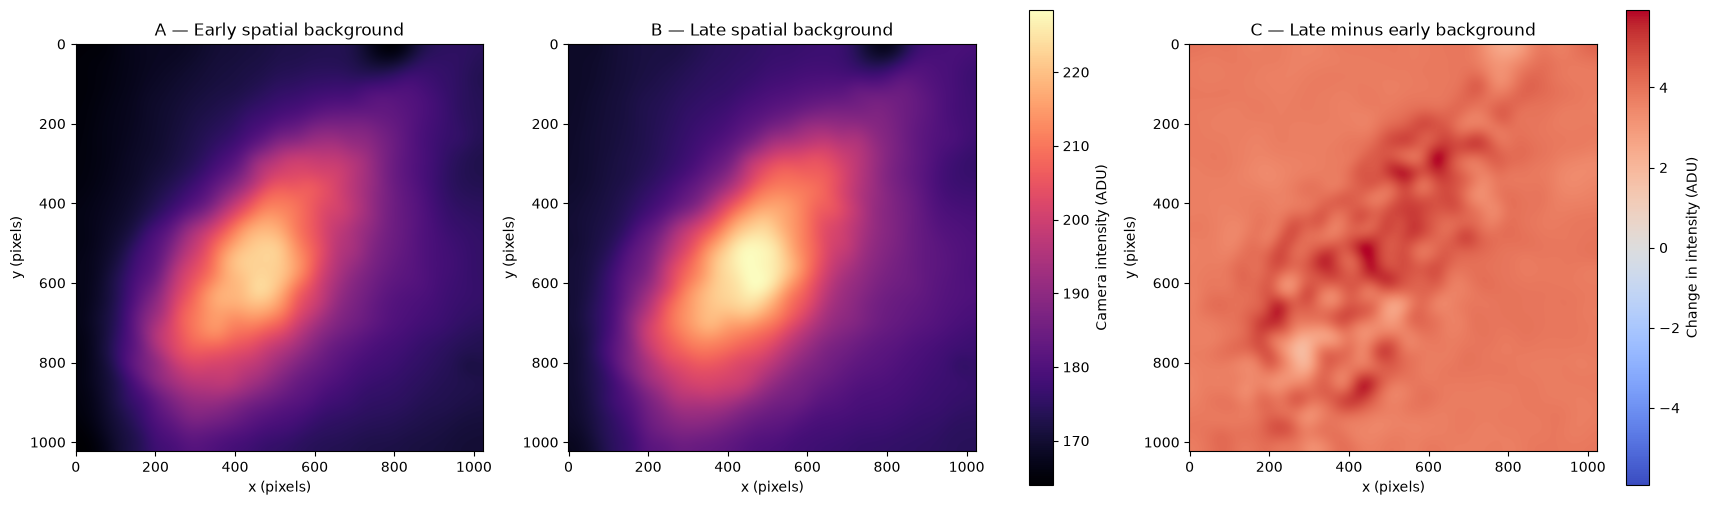

In [41]:

# Number of frames used for early/late comparison
N_WINDOW = 200

# Mean images using existing qd_blinking function
early_image, _ = projections(video[:N_WINDOW])
late_image, _ = projections(video[-N_WINDOW:])

# Apply the same filtering method as previously
early_background = gaussian_filter(
    median_filter(
        early_image,
        size=MEDIAN_SIZE,
        mode="reflect"
    ),
    sigma=SMOOTHING_SIGMA
)

late_background = gaussian_filter(
    median_filter(
        late_image,
        size=MEDIAN_SIZE,
        mode="reflect"
    ),
    sigma=SMOOTHING_SIGMA
)

# Difference in background intensity
background_difference = (
    late_background - early_background
)

# Shared colour scale for a fair visual comparison
vmin = min(
    early_background.min(),
    late_background.min()
)
vmax = max(
    early_background.max(),
    late_background.max()
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

im0 = axes[0].imshow(
    early_background,
    cmap="magma",
    vmin=vmin,
    vmax=vmax
)
axes[0].set_title("A — Early spatial background")

im1 = axes[1].imshow(
    late_background,
    cmap="magma",
    vmin=vmin,
    vmax=vmax
)
axes[1].set_title("B — Late spatial background")

im2 = axes[2].imshow(
    background_difference,
    cmap="coolwarm",
    vmin=-np.max(np.abs(background_difference)),
    vmax=np.max(np.abs(background_difference))
)
axes[2].set_title("C — Late minus early background")

for ax in axes:
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")

fig.colorbar(
    im1,
    ax=axes[:2],
    label="Camera intensity (ADU)"
)

fig.colorbar(
    im2,
    ax=axes[2],
    label="Change in intensity (ADU)"
)

plt.show()


As a note to remember meaning: In the third panel, blue indicates a decrease in recorded birghtness, red indicates an increase, and colours near the midpoint indicate little change.

## Quantify the change at each QD position ##
We'll use the candidate coordinates we've already extracted and compare the early and late background estimates at those positions.

This is particularly useful because it connects our new background analysis to the 168 retained candidates.

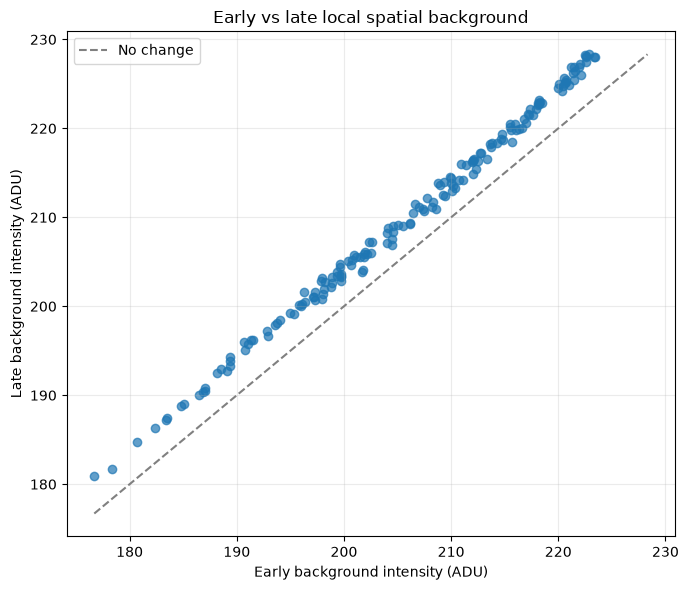

Mean background change: 4.14 ADU
Median background change: 4.25 ADU


,candidate_id,x,y,R,early_background,late_background,background_change
0,1,452.800828,706.836582,1.637609,210.760760,214.229529,3.468768
1,2,464.054173,601.701621,1.684931,223.389997,228.075364,4.685368
2,3,667.021776,430.300938,2.022593,199.370329,203.825986,4.455656
3,4,205.045549,768.342618,1.578358,194.071719,198.451522,4.379803
4,5,318.990623,635.325971,1.591299,211.936510,216.198625,4.262115
5,6,527.175193,591.486405,1.803162,218.223173,223.153070,4.929897
6,10,337.570626,437.032278,1.623447,193.742660,198.172041,4.429381
7,12,151.308710,786.949598,1.678072,183.404891,187.245494,3.840603
8,14,224.744872,732.201358,1.516674,199.381631,203.441876,4.060246
9,15,433.411902,558.475863,1.850405,222.021720,227.199673,5.177954


In [42]:

# Reuse existing candidate coordinates
x_idx = np.rint(candidates["x"]).astype(int).to_numpy()
y_idx = np.rint(candidates["y"]).astype(int).to_numpy()

background_comparison = candidates[
    ["candidate_id", "x", "y", "R"]
].copy()

background_comparison["early_background"] = (
    early_background[y_idx, x_idx]
)

background_comparison["late_background"] = (
    late_background[y_idx, x_idx]
)

background_comparison["background_change"] = (
    background_comparison["late_background"]
    - background_comparison["early_background"]
)

# Compare early and late local background
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    background_comparison["early_background"],
    background_comparison["late_background"],
    alpha=0.7
)

low = min(
    background_comparison["early_background"].min(),
    background_comparison["late_background"].min()
)

high = max(
    background_comparison["early_background"].max(),
    background_comparison["late_background"].max()
)

ax.plot(
    [low, high],
    [low, high],
    "--",
    color="grey",
    label="No change"
)

ax.set_xlabel("Early background intensity (ADU)")
ax.set_ylabel("Late background intensity (ADU)")
ax.set_title("Early vs late local spatial background")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(
    "Mean background change:",
    f"{background_comparison['background_change'].mean():.2f} ADU"
)

print(
    "Median background change:",
    f"{background_comparison['background_change'].median():.2f} ADU"
)

display(background_comparison.head(10))


- Points on the diagonal indicate approximately unchanged background brightness.
- Points below the diagonal indicate decreasing background brightness.
- Point above the diagonal indicate increasing background brightness.

An important detail is that the background values here indicate the camera's baseline offset. We should therefore compare absolute changes in ADU rather than divide by the raw background value and interpret that as a physical percentage loss.


## Examine how the background evolves throughout the recording ##
Comparing the first and last 200 frames tells us the overall change, but not *when* it happens.

For example, the background might decline steadily, drop suddenly, or remain stable before changing near the end. Hence, we will calculate a series of background maps over consecutive blocks of frames and examine three fixed spatial locations.



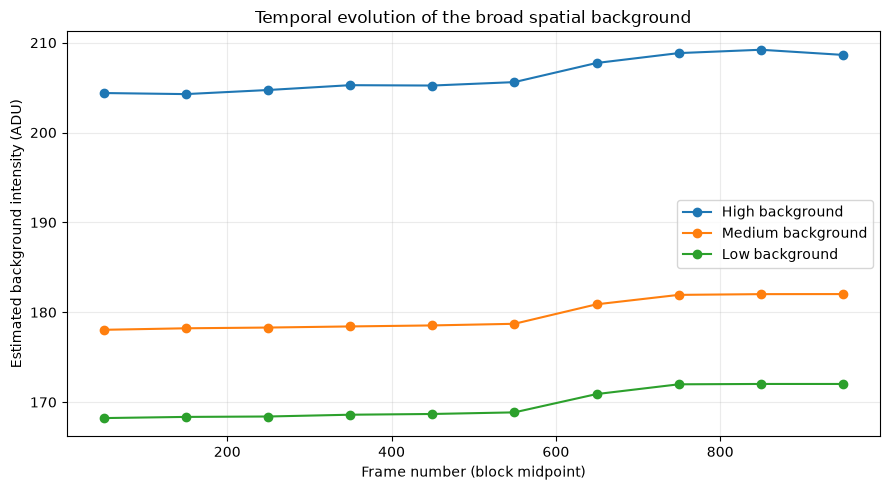

Selected positions (y, x): {'High': (np.int64(424), np.int64(411)), 'Medium': (np.int64(671), np.int64(891)), 'Low': (np.int64(117), np.int64(177))}


In [43]:

# Analyse the recording in blocks of 100 frames
BLOCK_SIZE = 100

# Select positions based on the first background map
# These are approximate high-, medium- and low-background regions.
y_peak, x_peak = np.unravel_index(
    np.argmax(early_background),
    early_background.shape
)

# Find representative locations from the early profile
flat_background = early_background.ravel()

target_levels = {
    "High": np.percentile(flat_background, 90),
    "Medium": np.percentile(flat_background, 50),
    "Low": np.percentile(flat_background, 10)
}

positions = {}

for name, target in target_levels.items():
    idx = np.argmin(
        np.abs(early_background - target)
    )
    positions[name] = np.unravel_index(
        idx, early_background.shape
    )

# Compute smoothed background for each block
block_centres = []
block_profiles = {name: [] for name in positions}

for start in range(0, len(video), BLOCK_SIZE):
    end = min(start + BLOCK_SIZE, len(video))

    if end - start < BLOCK_SIZE:
        continue

    block_mean, _ = projections(video[start:end])

    block_background = gaussian_filter(
        median_filter(
            block_mean,
            size=MEDIAN_SIZE,
            mode="reflect"
        ),
        sigma=SMOOTHING_SIGMA
    )

    block_centres.append((start + end - 1) / 2)

    for name, (y, x) in positions.items():
        block_profiles[name].append(
            block_background[y, x]
        )

fig, ax = plt.subplots(figsize=(9, 5))

for name, values in block_profiles.items():
    ax.plot(
        block_centres,
        values,
        marker="o",
        label=f"{name} background"
    )

ax.set_xlabel("Frame number (block midpoint)")
ax.set_ylabel("Estimated background intensity (ADU)")
ax.set_title("Temporal evolution of the broad spatial background")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Selected positions (y, x):", positions)


This is a first exploratory comparison rather than a fully validated background-tracking method. The selected locations are chosen from the inital profile, and we'll need to inspect whether any coincide with dark artefacts, unusually dense QD regions or other problematic features.

The 100-frame blocks also average over short-timescale blinking, which is appropriate for investigating broad background changes but not for resolving individual ON/OFF events.

## Analysis of these results ##

*Figure 1 - Early and late spatial background maps*

The first two panels show very similar spatial patterns. The bright, elongated region remains in approximately the same location, but appears slightly brighter towards the end of the recording.

The difference map (pancel C) is predominantly red, indicating an increase in background brightness. There are also localised regions showing smaller changes, particularly around the central fluorescence-rich area.

This suggests that the broad spatial background is not completely stationary throughout the recording. 

However, the smaller-scale features in the difference map could reflect changes in QD fluorescence, sample conditions, or imperfect suppression of localised features during the filtering process.

The background increase should therefore not automatically be attributed to an increase in excitation laser power.

*Figure 2 - Early versus late local spatial background*

This graph compares the estimated background intensity during the first and last 200 frames at the positions of the 168 retained QD candidates.

All points lie above the dashed diagonal, indicating that the local spatial background increased during the recording. 

The calcaulted changes were:
- Mean background change = +4.14 ADU
- Median background change = +4.25 ADU

The similarity between these values suggests that the increase is reasonably consistent across the candidate population rather than being dominated by a small number of extreme values.

The points also follow a relatively narrow trend, suggesting that the spatial brightness distribution remain broadly similar despite the overall increase.

*Figure 3 - Temporal evolution of the broad spatial background*
The third figure examines how the estimated background evolves throughout the recording using consecutive 100-frame blocks at three representative locations.

All three regions show a gradual increase in background intensity, with a more noticeable rise occuring after approximately frame 600.

The approximate changes are:
- High-background region : 204 to 208 ADU
- Medium-background region: 178 to 182 ADU
- Low-background region: 168 to 172 ADU

The similar absolute increases across the three regions suggest that a shared additive contribution to the recorded background may be present.

One possible explanation is a change in the camera baseline or another common background component, although this cannot currently be confirmed.

Importantly, the differences between the three background levels remain approximately constant throughout the recording, suggesting that the overall spatial brightness pattern is relatively stable. 

## Overal Interpretation ##
The most important finding is that the broad spatial background increases slightly over time, while the background-corrected fluorescence intensity of most QD candidates decreases substantially.

Previous analysis showed that most candidates lost approximately 80-100% of their background-corrected fluorescence, whereas the broad spatial background increased by an average of 4.14 ADU.

This indicates that the broad background and the localised QD fluorescence signals exhibit different temporal behaviour. 

The results make a simple explanation based on a uniform decrease in the recorded background less convincing. However, they do not establish photobleaching or photodarkening as the cause of the fluorescence decline, since illumination changes, focus drift and other experimental effects have not yet been excluded. 

An important distinction is that the smoothed spatial background is not equivalent to the local annular background used to correct individual QD fluorescence traces.